In [7]:
import time
import hashlib
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import psutil
    HAS_PSUTIL = True
except ImportError:
    HAS_PSUTIL = False
    print("psutil не установлен — источник будет только джиттер таймера")

np.random.seed(None)
plt.rcParams['figure.figsize'] = (10, 4)

In [8]:
class VoltageNoiseRNG:
    """
    Генератор U(0,1) на основе физического джиттера таймера
    и (опционально) колебаний частоты CPU как косвенного признака
    колебаний напряжения питания.
    """
    def __init__(self, pool_size=4096):
        self.pool_size = pool_size
        self._pool = []
        self._counter = 0
        self._refill()

    def _raw_entropy(self):
        # младшие биты таймера — физический джиттер
        t = time.perf_counter_ns()
        # разница между двумя замерами — усиливает джиттер
        t2 = time.perf_counter_ns()
        jitter = t2 - t
        # частота CPU (колеблется вместе с питанием/нагрузкой)
        freq = 0
        if HAS_PSUTIL:
            try:
                freq = int(psutil.cpu_freq().current * 1000)  # кГц
            except Exception:
                freq = 0
        # pid и счётчик — чтобы не было повторов
        self._counter += 1
        return f"{jitter}|{t}|{freq}|{os.getpid()}|{self._counter}".encode()

    def _refill(self):
        buf = bytearray()
        while len(buf) < self.pool_size:
            buf += hashlib.blake2b(self._raw_entropy(), digest_size=32).digest()
        self._pool = list(buf[:self.pool_size])

    def random(self):
        if not self._pool:
            self._refill()
        b = self._pool.pop()
        return b / 256.0  # [0, 1)

    def random_array(self, n):
        return np.array([self.random() for _ in range(n)])

Сгенерировано 100000 чисел за 0.03 с (3,448,271 чисел/с)
min = 0.000000, max = 0.996094
mean = 0.498912 (ожидается 0.5)
var  = 0.083343 (ожидается 0.083333)


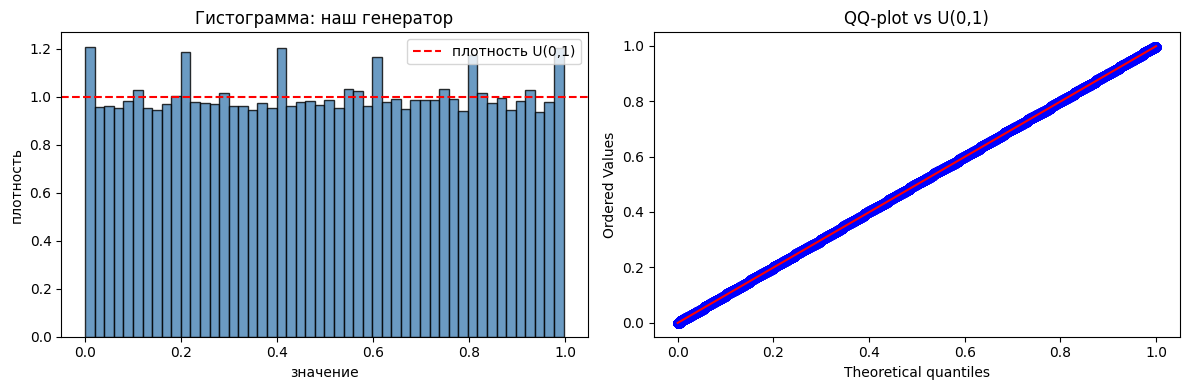

In [9]:
N = 100_000
rng = VoltageNoiseRNG()

t0 = time.time()
samples = rng.random_array(N)
elapsed = time.time() - t0

print(f"Сгенерировано {N} чисел за {elapsed:.2f} с ({N/elapsed:,.0f} чисел/с)")
print(f"min = {samples.min():.6f}, max = {samples.max():.6f}")
print(f"mean = {samples.mean():.6f} (ожидается 0.5)")
print(f"var  = {samples.var():.6f} (ожидается {1/12:.6f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(samples, bins=50, density=True, color='steelblue', edgecolor='black', alpha=0.8)
ax[0].axhline(1.0, color='red', linestyle='--', label='плотность U(0,1)')
ax[0].set_title('Гистограмма: наш генератор')
ax[0].set_xlabel('значение')
ax[0].set_ylabel('плотность')
ax[0].legend()

# QQ-plot против равномерного
stats.probplot(samples, dist="uniform", plot=ax[1])
ax[1].set_title('QQ-plot vs U(0,1)')

plt.tight_layout()
plt.show()

=== Хи-квадрат (20 бинов) ===
Наш генератор:  chi2 =   108.09,  df = 19,  p-value = 0.0000
Python random:  chi2 =     5.56,  df = 19,  p-value = 0.9988
(p > 0.05 — нет оснований отвергнуть равномерность)


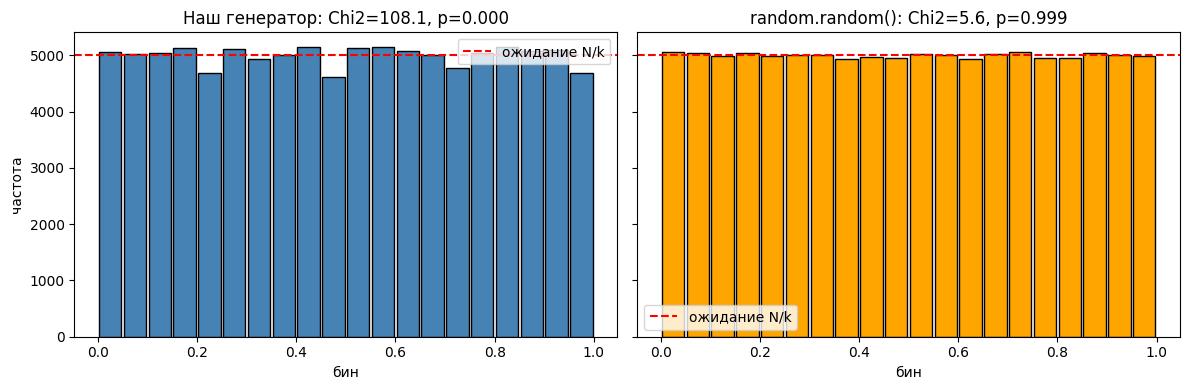

In [ ]:
def chi2_uniform(data, bins=20):
    data = np.asarray(data)
    data = data[(data >= 0) & (data < 1)]
    counts, edges = np.histogram(data, bins=bins, range=(0, 1))
    expected = len(data) / bins
    chi2 = ((counts - expected) ** 2 / expected).sum()
    df = bins - 1
    p = stats.chi2.sf(chi2, df)
    return chi2, df, p, counts, edges

# свой генератор
chi2_own, df, p_own, counts_own, edges = chi2_uniform(samples, bins=20)

# базовый
baseline = np.random.random(N)
chi2_base, _, p_base, counts_base, _ = chi2_uniform(baseline, bins=20)

print("=== Хи-квадрат (20 бинов) ===")
print(f"Наш генератор:  chi2 = {chi2_own:8.2f},  df = {df},  p-value = {p_own:.4f}")
print(f"Python random:  chi2 = {chi2_base:8.2f},  df = {df},  p-value = {p_base:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
centers = (edges[:-1] + edges[1:]) / 2
ax[0].bar(centers, counts_own, width=1/20*0.9, color='steelblue', edgecolor='black')
ax[0].axhline(N/20, color='red', linestyle='--', label='ожидание N/k')
ax[0].set_title(f'Наш генератор: Chi2={chi2_own:.1f}, p={p_own:.3f}')
ax[0].set_xlabel('бин'); ax[0].set_ylabel('частота'); ax[0].legend()

ax[1].bar(centers, counts_base, width=1/20*0.9, color='orange', edgecolor='black')
ax[1].axhline(N/20, color='red', linestyle='--', label='ожидание N/k')
ax[1].set_title(f'random.random(): Chi2={chi2_base:.1f}, p={p_base:.3f}')
ax[1].set_xlabel('бин'); ax[1].legend()

plt.tight_layout(); plt.show()

In [13]:
import math
import time

def pi_monte_carlo(samples_x, samples_y):
    """
    Оценка Pi по уже сгенерированным парам (x, y) ~ U(0,1).
    Точки внутри четверти круга: x^2 + y^2 <= 1.
    """
    inside = np.sum(samples_x**2 + samples_y**2 <= 1.0)
    n = len(samples_x)
    return 4.0 * inside / n, inside

def pi_own(rng, n):
    s = rng.random_array(2 * n)
    return pi_monte_carlo(s[:n], s[n:])

def pi_base(n):
    s = np.random.random(2 * n)
    return pi_monte_carlo(s[:n], s[n:])

# быстрая проверка
est, _ = pi_own(rng, 100_000)
print(f"Пробный прогон (N=100_000): Pi= {est:.4f},  ошибка = {abs(est - math.pi):.4f}")

Пробный прогон (N=100_000): Pi= 3.1492,  ошибка = 0.0076


In [12]:
Ns = [100, 1_000, 10_000, 100_000, 1_000_000]

results = []
for n in Ns:
    t0 = time.time(); est_own, _ = pi_own(rng, n); t_own = time.time() - t0
    t0 = time.time(); est_base, _ = pi_base(n);      t_base = time.time() - t0
    results.append((n, est_own, abs(est_own - math.pi), t_own,
                       est_base, abs(est_base - math.pi), t_base))

print(f"{'N':>10} | {'Pi':>9} {'|err|':>8} {'t,с':>7} | {'Pi_random':>9} {'|err|':>8} {'t,с':>7}")
print("-" * 70)
for r in results:
    n, e1, d1, t1, e2, d2, t2 = r
    print(f"{n:>10} | {e1:>9.5f} {d1:>8.5f} {t1:>7.3f} | {e2:>9.5f} {d2:>8.5f} {t2:>7.3f}")

         N |        Pi    |err|     t,с | Pi_random    |err|     t,с
----------------------------------------------------------------------
       100 |   3.08000  0.06159   0.000 |   3.24000  0.09841   0.000
      1000 |   3.18400  0.04241   0.001 |   3.13200  0.00959   0.000
     10000 |   3.16240  0.02081   0.006 |   3.13680  0.00479   0.000
    100000 |   3.16248  0.02089   0.060 |   3.14116  0.00043   0.002
   1000000 |   3.15904  0.01745   0.601 |   3.14189  0.00030   0.024
